# 4장 word2vec 한글 실습: 네이버 영화 리뷰로 CBOW 학습

교재 4장 CBOW를 네이버 영화 리뷰(NSMC)로 학습하고 평가했다.

영화 리뷰를 고른 이유는 두 가지다.
- 평가하는 표현(최고, 노잼, 몰입감)과 구어체·신조어가 많아서 word2vec이 이런 말을 어떻게 배우는지 보고 싶었다.
- 리뷰마다 긍정/부정 라벨이 있어서 단어 벡터를 감성 분류 정확도로도 평가할 수 있다.

데이터 읽기, 전처리, 평가 코드만 새로 작성했고 `CBOW`, `Trainer`, `Adam`, `most_similar()`, `analogy()`는 교재 코드를 그대로 썼다.

In [1]:
# Colab에서 실행할 때 필요한 준비
def is_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

if is_colab():
    !git clone https://github.com/paragon0730/DeepLearning_Project2.git
    %cd DeepLearning_Project2/ch04
    !apt-get -qq install fonts-nanum > /dev/null   # 그래프의 한글 표시용 폰트
    import matplotlib.font_manager as fm; fm._load_fontmanager(try_read_cache=False)

import sys
import os
sys.path.append(os.pardir)  # 부모 디렉터리의 파일을 가져올 수 있도록 설정

## 1. 데이터

[NSMC](https://github.com/e9t/nsmc): 네이버 영화 리뷰 20만 건(CC0). 형식은 `id / document / label`이고 label은 1(긍정), 0(부정)이다.

word2vec 학습에는 train 15만 건만 쓰고, test 5만 건은 감성 분류 평가용으로 남겨 두었다.

In [2]:
import collections
import numpy as np

def load_nsmc(path):
    texts, labels = [], []
    with open(path, encoding='utf-8') as f:
        next(f)  # 헤더(id, document, label) 건너뛰기
        for line in f:
            _id, text, label = line.rstrip('\n').split('\t')
            if text.strip():          # 내용이 빈 리뷰는 버린다
                texts.append(text)
                labels.append(int(label))
    return texts, np.array(labels)

train_texts, train_labels = load_nsmc('../dataset/ratings_train.txt')
test_texts, test_labels = load_nsmc('../dataset/ratings_test.txt')

print('train 리뷰: %d건 (긍정 비율 %.1f%%)' % (len(train_texts), 100 * train_labels.mean()))
print('test  리뷰: %d건 (긍정 비율 %.1f%%)' % (len(test_texts), 100 * test_labels.mean()))
print('리뷰 평균 길이: %.1f글자' % np.mean([len(t) for t in train_texts]))
print()
for t, l in list(zip(train_texts, train_labels))[:8]:
    print('[%s] %s' % ('긍정' if l else '부정', t))

train 리뷰: 149995건 (긍정 비율 49.9%)
test  리뷰: 49997건 (긍정 비율 50.3%)
리뷰 평균 길이: 35.2글자

[부정] 아 더빙.. 진짜 짜증나네요 목소리
[긍정] 흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나
[부정] 너무재밓었다그래서보는것을추천한다
[부정] 교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정
[긍정] 사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 던스트가 너무나도 이뻐보였다
[부정] 막 걸음마 뗀 3세부터 초등학교 1학년생인 8살용영화.ㅋㅋㅋ...별반개도 아까움.
[부정] 원작의 긴장감을 제대로 살려내지못했다.
[부정] 별 반개도 아깝다 욕나온다 이응경 길용우 연기생활이몇년인지..정말 발로해도 그것보단 낫겟다 납치.감금만반복반복..이드라마는 가족도없다 연기못하는사람만모엿네


## 2. 전처리와 토큰화

수업 예제의 `common/korean.py` `tokenize()`로 조사를 분리했다(`영화를` → `영화`, `-를`).
`ㅋㅋㅋㅋㅋ`, `.....`처럼 반복된 문자는 2개까지만 남겼다. 리뷰 사이에는 `<eos>`를 넣었다.

In [3]:
import re
from common.korean import tokenize

def normalize_review(text):
    text = re.sub(r'([ㄱ-ㅎㅏ-ㅣ])\1{2,}', r'\1\1', text)   # ㅋㅋㅋㅋ -> ㅋㅋ, ㅠㅠㅠ -> ㅠㅠ
    text = re.sub(r'([.!?~])\1+', r'\1\1', text)           # ..... -> .., !!!! -> !!
    return text

def review_tokens(text):
    return tokenize(normalize_review(text))

for t in train_texts[:5]:
    print(t)
    print('  ->', review_tokens(t))

아 더빙.. 진짜 짜증나네요 목소리
  -> ['아', '더빙', '..', '진짜', '짜증나네요', '목소리']
흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나
  -> ['흠', '..', '포스터보고', '초딩영화줄', '..', '오버연기', '-조차', '가볍지', '않구', '-나']
너무재밓었다그래서보는것을추천한다
  -> ['너무재밓었다그래서보는것을추천한다']
교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정
  -> ['교도소', '이야기구먼', '..', '솔직히', '재미', '-는', '없다', '..', '평점', '조정']
사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 던스트가 너무나도 이뻐보였다
  -> ['사이몬페그', '-의', '익살스런', '연기', '-가', '돋보였던', '영화', '!', '스파이더맨', '-에서', '늙어보이기', '-만', '했던', '커스틴', '던스트', '-가', '너무나', '-도', '이뻐보였다']


## 3. 단어 ID 변환

오타와 띄어쓰기 때문에 어휘가 22만 개가 넘는다. PTB처럼 자주 나온 1만 개만 남기고 나머지는 `<unk>`로 바꿨다.

In [4]:
vocab_limit = 10000  # PTB와 같은 어휘 수

words = []
for t in train_texts:
    words += review_tokens(t)
    words.append('<eos>')

counts = collections.Counter(words)
keep = set(w for w, _ in counts.most_common(vocab_limit - 1))   # 나머지 한 자리는 <unk>
words = [w if w in keep else '<unk>' for w in words]

word_to_id = {}
id_to_word = {}
for word in words:
    if word not in word_to_id:
        new_id = len(word_to_id)
        word_to_id[word] = new_id
        id_to_word[new_id] = word
corpus = np.array([word_to_id[w] for w in words])
vocab_size = len(word_to_id)

print('말뭉치 크기: %d 토큰' % len(corpus))
print('전체 어휘 수: %d  ->  상위 %d개만 사용' % (len(counts), vocab_size))
print('<unk> 비율: %.1f%%' % (100 * np.mean(corpus == word_to_id['<unk>'])))
print('1만 번째 단어의 등장 횟수: %d' % counts.most_common(vocab_limit - 1)[-1][1])
print('자주 나온 단어:', [w for w, _ in collections.Counter(words).most_common(60)
                         if w not in ('<unk>', '<eos>')])

말뭉치 크기: 1951368 토큰
전체 어휘 수: 227625  ->  상위 10000개만 사용
<unk> 비율: 18.0%
1만 번째 단어의 등장 횟수: 12
자주 나온 단어: ['.', '..', '-이', '-가', '-는', '영화', '-도', '-의', '-에', ',', '-을', '-은', '-만', '-를', '?', '-로', '!', '너무', 'ㅋㅋ', '"', '-나', '정말', '~', '-으로', '!!', ';', '진짜', '^', '-에서', '-과', '이', '1', '연기', '평점', '-와', '스토리', '최고', '내', '10', '그냥', '왜', '이런', '점', '-까지', '그', '더', '것', '나', '2', '-', '드라마', '다', '수', '-보다', '내용', '~~', 'ㅠㅠ', '보고']


## 4. CBOW 학습

교재 `train.py`와 같은 코드이고 하이퍼파라미터만 바꿨다.

| | 교재(PTB) | 여기 |
|---|---|---|
| window_size | 5 | 5 |
| hidden_size | 100 | 100 |
| batch_size | 100 | 500 |
| Adam lr | 0.001 | 0.005 |
| max_epoch | 10 | 4 |

batch 100으로는 CPU에서 1에폭에 20분 넘게 걸렸다. 매 반복마다 Adam이 가중치 행렬 전체를 갱신하는 비용이 커서 batch를 500으로 늘렸고(1에폭 약 9분), 갱신 횟수가 줄어든 만큼 학습률을 올렸다.

학습 데이터(맥락, 타깃) 쌍: 1951358
| 에폭 1 |  반복 1 / 3902 | 시간 0[s] | 손실 4.16
| 에폭 1 |  반복 501 / 3902 | 시간 69[s] | 손실 2.56
| 에폭 1 |  반복 1001 / 3902 | 시간 137[s] | 손실 2.29
| 에폭 1 |  반복 1501 / 3902 | 시간 208[s] | 손실 2.18
| 에폭 1 |  반복 2001 / 3902 | 시간 281[s] | 손실 2.12
| 에폭 1 |  반복 2501 / 3902 | 시간 352[s] | 손실 2.07
| 에폭 1 |  반복 3001 / 3902 | 시간 422[s] | 손실 2.03
| 에폭 1 |  반복 3501 / 3902 | 시간 493[s] | 손실 2.00
| 에폭 2 |  반복 1 / 3902 | 시간 549[s] | 손실 1.97
| 에폭 2 |  반복 501 / 3902 | 시간 619[s] | 손실 1.88
| 에폭 2 |  반복 1001 / 3902 | 시간 687[s] | 손실 1.87
| 에폭 2 |  반복 1501 / 3902 | 시간 756[s] | 손실 1.87
| 에폭 2 |  반복 2001 / 3902 | 시간 826[s] | 손실 1.87
| 에폭 2 |  반복 2501 / 3902 | 시간 894[s] | 손실 1.86
| 에폭 2 |  반복 3001 / 3902 | 시간 960[s] | 손실 1.86
| 에폭 2 |  반복 3501 / 3902 | 시간 1028[s] | 손실 1.85
| 에폭 3 |  반복 1 / 3902 | 시간 1081[s] | 손실 1.84
| 에폭 3 |  반복 501 / 3902 | 시간 1147[s] | 손실 1.73
| 에폭 3 |  반복 1001 / 3902 | 시간 1213[s] | 손실 1.74
| 에폭 3 |  반복 1501 / 3902 | 시간 1280[s] | 손실 1.74
| 에폭 3 |  반복 2001 / 3902 | 시간 1345[s] | 손실 1

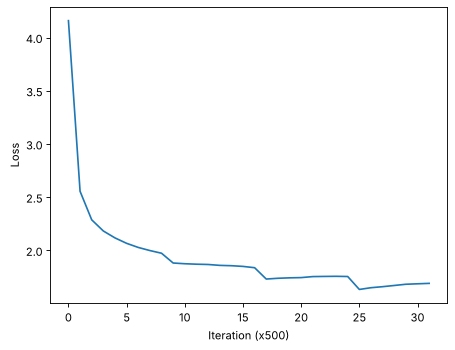

In [5]:
from common.trainer import Trainer
from common.optimizer import Adam
from common.util import create_contexts_target
from cbow import CBOW

# 하이퍼파라미터 설정
window_size = 5
hidden_size = 100
batch_size = 500
max_epoch = 4
np.random.seed(1234)

contexts, target = create_contexts_target(corpus, window_size)
print('학습 데이터(맥락, 타깃) 쌍:', len(target))

# 모델 등 생성
model = CBOW(vocab_size, hidden_size, window_size, corpus)
optimizer = Adam(lr=0.005)
trainer = Trainer(model, optimizer)

# 학습 시작
trainer.fit(contexts, target, max_epoch, batch_size, eval_interval=500)
trainer.plot()

In [6]:
import pickle

# 나중에 학습 없이 평가만 할 수 있도록 저장(교재 train.py와 같은 형식)
params = {}
params['word_vecs'] = model.word_vecs.astype(np.float16)
params['word_to_id'] = word_to_id
params['id_to_word'] = id_to_word
pkl_file = 'cbow_params_movie.pkl'
with open(pkl_file, 'wb') as f:
    pickle.dump(params, f, -1)
print('저장:', pkl_file, '(%.1f MB)' % (os.path.getsize(pkl_file) / 1e6))

저장: cbow_params_movie.pkl (2.2 MB)


## 5. 저장한 벡터 불러오기

평가는 저장한 `cbow_params_movie.pkl`을 읽어서 한다. 학습을 건너뛰려면 1~3절을 실행하고 여기서부터 실행하면 된다.

In [7]:
import pickle
import numpy as np

with open('cbow_params_movie.pkl', 'rb') as f:
    params = pickle.load(f)
word_vecs = params['word_vecs'].astype(np.float32)
word_to_id = params['word_to_id']
id_to_word = params['id_to_word']
vocab_size = len(word_to_id)
print('단어 벡터 행렬:', word_vecs.shape)

단어 벡터 행렬: (10000, 100)


## 6. 비슷한 단어: `most_similar()`

영화 구성 요소, 장르, 평가 표현, 인터넷 표현으로 나눠 질의했다.

In [8]:
from common.util import most_similar, analogy

querys = ['배우', '감독', '스토리', '연출', '음악', 'CG',
          '공포', '로맨스', '애니', '성룡',
          '최고', '명작', '감동', '재밌다', '노잼', '쓰레기',
          'ㅋㅋ', 'ㅠㅠ']
for query in querys:
    most_similar(query, word_to_id, id_to_word, word_vecs, top=5)


[query] 배우
 여배우: 0.7053067088127136
 주연배우: 0.5800272822380066
 배우들: 0.5747074484825134
 연기자: 0.5677338242530823
 안성기: 0.5578054189682007

[query] 감독
 제작진: 0.538882315158844
 제작진들: 0.5283145308494568
 연기들: 0.5200175046920776
 명감독: 0.5026301145553589
 패틴슨: 0.4922535717487335

[query] 스토리
 시나리오: 0.7483838796615601
 줄거리: 0.6369756460189819
 내용전개: 0.6112247705459595
 내용: 0.5598791837692261
 내러티브: 0.5394364595413208

[query] 연출
 구성: 0.708508312702179
 연출력: 0.6948606967926025
 편집: 0.6595740914344788
 각본: 0.6167974472045898
 배우들: 0.590588390827179

[query] 음악
 영상: 0.7912073135375977
 배경음악: 0.6833318471908569
 색감: 0.6737242937088013
 그림: 0.6380907893180847
 배경: 0.616815984249115

[query] CG
 cg: 0.7922616004943848
 OST: 0.657899796962738
 ost: 0.6239274144172668
 TV: 0.5127502083778381
 bgm: 0.493328332901001

[query] 공포
 스릴러: 0.683681070804596
 장르: 0.6103255748748779
 호러: 0.573101282119751
 미스테리: 0.5387726426124573
 로맨스: 0.5380864143371582

[query] 로맨스
 코미디: 0.6543396711349487
 판타지: 0.6475945

- 같은 종류의 말이 잘 모였다: 스토리 → 시나리오·줄거리, 명작 → 걸작·대작·수작, 성룡 → 이연걸·무술.
- 표기만 다른 말도 모였다: CG ↔ cg, 노잼 → 씹노잼·개노잼, ㅠㅠ → ㅜㅜ, 쓰레기 → 쓰래기.
- 반의어도 가깝게 나온다. `최고`와 가장 가까운 단어가 `최악`이다. 문맥이 거의 같기 때문이다.

## 7. 유추: `analogy()`

`a : b = c : ?`를 `b - a + c`와 가장 가까운 단어로 푼다. 먼저 교재 방식 그대로 실행했다.

In [9]:
analogy('공포영화', '무서운', '코미디', word_to_id, id_to_word, word_vecs, answer='웃긴')
analogy('한국', '한국영화', '일본', word_to_id, id_to_word, word_vecs, answer='일본영화')


[analogy] 공포영화:무서운 = 코미디:?
==>웃긴:4.597038
 알게해줬다: 5.440965175628662
 돈아까운: 5.10648775100708
 보고싶: 5.10395622253418
 괜찮았던: 4.657793045043945
 다시보고싶: 4.621668338775635

[analogy] 한국:한국영화 = 일본:?
==>일본영화:4.1072927
 점준것중: 5.421255588531494
 점주: 5.061474800109863
 점준거중: 4.859805107116699
 류영화: 4.6136579513549805
 종류: 4.450725555419922


정답 점수가 높은데도 1등이 엉뚱하다. 교재 `analogy()`는 단어 행렬을 정규화하지 않아서 벡터 길이가 긴 드문 단어(`점주`, `점준것중`)가 유리하다. 단어 행렬을 정규화해서 다시 풀었다.

In [10]:
from common.util import normalize

word_vecs_n = normalize(word_vecs.copy())   # 각 행(단어 벡터)을 길이 1로

questions = [
    ('공포영화', '무서운', '코미디', '웃긴'),        # 공포영화는 무서운, 코미디는?
    ('한국', '한국영화', '일본', '일본영화'),
    ('남자', '여자', '남주', '여주'),                # 남주인공 : 여주인공
    ('남자', '여자', '아빠', '엄마'),
    ('최고', '명작', '최악', '졸작'),
    ('재밌다', '꿀잼', '재미없다', '노잼'),
    ('성룡', '홍콩', '디즈니', '미국'),
    ('배우', '연기', '감독', '연출'),
]
for a, b, c, d in questions:
    analogy(a, b, c, word_to_id, id_to_word, word_vecs_n, answer=d)


[analogy] 공포영화:무서운 = 코미디:?
==>웃긴:0.55459625
 웃긴: 0.5545961856842041
 재미있는: 0.5395820140838623
 볼만한: 0.5306111574172974
 유쾌한: 0.5262601971626282
 어이없는: 0.510597825050354

[analogy] 한국:한국영화 = 일본:?
==>일본영화:0.5103841
 일본영화: 0.5103840827941895
 가족영화: 0.4551551640033722
 조폭영화: 0.45080476999282837
 종류: 0.44641929864883423
 향수: 0.44296497106552124

[analogy] 남자:여자 = 남주:?
==>여주:0.70055825
 여주: 0.7005583047866821
 아줌마: 0.524667501449585
 여자애: 0.5080569982528687
 외모: 0.5046998858451843
 몸매: 0.49709537625312805

[analogy] 남자:여자 = 아빠:?
==>엄마:0.5523764
 아이: 0.5571966767311096
 엄마: 0.552376389503479
 남친: 0.5429576635360718
 딸아이: 0.5355868339538574
 누나: 0.5213215947151184

[analogy] 최고:명작 = 최악:?
==>졸작:0.59353757
 망작: 0.6435375809669495
 졸작: 0.5935376286506653
 걸작: 0.5213906764984131
 쓰레기다: 0.5022021532058716
 대작: 0.49698662757873535

[analogy] 재밌다:꿀잼 = 재미없다:?
==>노잼:0.37879115
 재미없음: 0.5640113353729248
 짜증나네: 0.5331196188926697
 재미없네: 0.49465811252593994
 기대이하: 0.4864763021469116
 재미없어: 0.483768641948

- 8문제 중 3문제(웃긴, 일본영화, 여주)는 1등, 2문제(엄마, 졸작)는 2등으로 맞혔다.
- `배우:연기 = 감독:?`은 연기력, 열연처럼 `연기`와 비슷한 말만 나왔다.
- 자주 나오는 관계는 어느 정도 풀지만, 일반적인 유추 문제는 이 정도 말뭉치로는 부족하다.

## 8. 감성 분류

리뷰에 나온 단어 벡터의 평균을 입력으로 로지스틱 회귀를 학습했다(train 15만 건). 평가는 학습에 쓰지 않은 test 5만 건으로 했고, 비교용으로 무작위 벡터도 같은 방식으로 돌렸다.

In [11]:
def review_vectors(texts, W):
    W = W / (np.linalg.norm(W, axis=1, keepdims=True) + 1e-8)   # 단어 벡터를 길이 1로 정규화
    unk = word_to_id['<unk>']
    X = np.zeros((len(texts), W.shape[1]), dtype=np.float32)
    for i, t in enumerate(texts):
        ids = [word_to_id[w] for w in review_tokens(t) if word_to_id.get(w, unk) != unk]
        if ids:
            X[i] = W[ids].mean(axis=0)
    return X

def train_logistic(X, y, lr=0.5, epochs=1000):
    '''로지스틱 회귀(전체 배치 경사하강법). 표준화 계수도 함께 돌려준다.'''
    mu, sd = X.mean(axis=0), X.std(axis=0) + 1e-8
    Xs = (X - mu) / sd
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(epochs):
        p = 1 / (1 + np.exp(-(Xs @ w + b)))
        w -= lr * Xs.T @ (p - y) / len(y)
        b -= lr * np.mean(p - y)
    return w, b, mu, sd

def accuracy(X, y, w, b, mu, sd):
    return np.mean((((X - mu) / sd) @ w + b > 0) == y)

W_trained = word_vecs
W_random = np.random.RandomState(0).randn(*W_trained.shape).astype(np.float32)

results = {}
for name, W in [('무작위 벡터', W_random), ('word2vec(CBOW) 벡터', W_trained)]:
    X_train, X_test = review_vectors(train_texts, W), review_vectors(test_texts, W)
    w, b, mu, sd = train_logistic(X_train, train_labels)
    results[name] = (w, b, mu, sd)
    print('%-20s train 정확도 %.1f%%   test 정확도 %.1f%%'
          % (name, 100 * accuracy(X_train, train_labels, w, b, mu, sd),
             100 * accuracy(X_test, test_labels, w, b, mu, sd)))

무작위 벡터               train 정확도 63.1%   test 정확도 62.7%
word2vec(CBOW) 벡터    train 정확도 79.4%   test 정확도 78.5%


test 정확도가 무작위 벡터 62.7%에서 word2vec 벡터 78.5%로 올랐다. 무작위 벡터도 62%가 나오는 건 어떤 단어가 들어 있는지만으로도 어느 정도 맞힐 수 있기 때문이다.

분류기 가중치 방향으로 단어를 투영해서 긍정/부정 쪽 단어를 뽑아 봤다.

In [12]:
w, b, mu, sd = results['word2vec(CBOW) 벡터']
Wn = W_trained / (np.linalg.norm(W_trained, axis=1, keepdims=True) + 1e-8)
score = ((Wn - mu) / sd) @ w

freq = collections.Counter(words)
cand = [i for i in range(vocab_size)
        if freq[id_to_word[i]] >= 50 and ('가' <= id_to_word[i][0] <= '힣' or id_to_word[i][0] in 'ㅋㅎㅠㅜㅡ')]
order = sorted(cand, key=lambda i: score[i])
print('가장 긍정 쪽 단어:', [id_to_word[i] for i in order[::-1][:25]])
print()
print('가장 부정 쪽 단어:', [id_to_word[i] for i in order[:25]])

가장 긍정 쪽 단어: ['감동적이고', '재밌고', '사랑스럽고', '재미있고', '따뜻하고', '따뜻해지', '잔잔하고', '순수하고', '그려낸', '지난', '아름답고', '깊은', '강추', '유쾌하게', '다시한번', '다양한', '멋지다', '슬프고', '현실적이고', '귀엽고', '훈훈한', '유쾌하고', '순수한', '한번쯤', '더욱']

가장 부정 쪽 단어: ['쳐', '이상하고', '말도안되는', '재미도없고', '유치', '답답하고', '유치하고', '지루하고', '대충', '제작비', '돈내고', '허접', '앞뒤', '짜증난다', '삼류', '싸구려', '아나', '허접한', '따위', '잔뜩', '쓰레기다', '관객', '미화', '돈', '만들었는지']


## 9. 시각화

SVD로 100차원 벡터를 2차원으로 줄였다.

matplotlib 한글 폰트: Noto Sans CJK KR


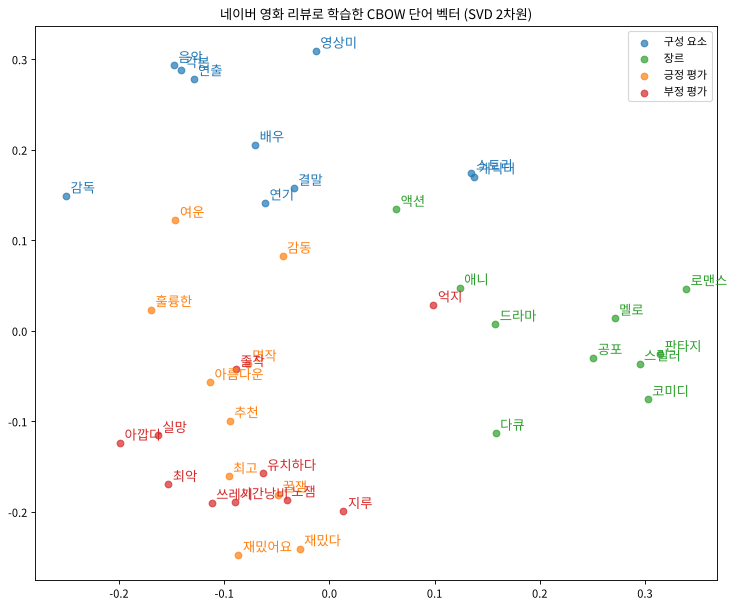

In [13]:
import matplotlib.pyplot as plt
from common.korean import set_korean_font

set_korean_font()

groups = {
    '구성 요소': ['배우', '감독', '스토리', '연기', '연출', '음악', '영상미', '각본', '캐릭터', '결말'],
    '장르':     ['공포', '액션', '로맨스', '코미디', '스릴러', '애니', '드라마', '다큐', '멜로', '판타지'],
    '긍정 평가': ['최고', '명작', '감동', '재밌다', '꿀잼', '추천', '훌륭한', '아름다운', '여운', '재밌어요'],
    '부정 평가': ['최악', '쓰레기', '노잼', '지루', '실망', '아깝다', '졸작', '유치하다', '시간낭비', '억지'],
}
colors = {'구성 요소': 'tab:blue', '장르': 'tab:green', '긍정 평가': 'tab:orange', '부정 평가': 'tab:red'}

show = [(w, g) for g, ws in groups.items() for w in ws if w in word_to_id]
missing = [w for ws in groups.values() for w in ws if w not in word_to_id]
if missing:
    print('어휘에 없어서 뺀 단어:', missing)

W = np.array([word_vecs[word_to_id[w]] for w, _ in show], dtype='f')
W = W / np.linalg.norm(W, axis=1, keepdims=True)
W = W - W.mean(axis=0)
U, S, V = np.linalg.svd(W)

plt.figure(figsize=(11, 9))
for g in groups:
    idx = [i for i, (_, gg) in enumerate(show) if gg == g]
    plt.scatter(U[idx, 0], U[idx, 1], c=colors[g], label=g, alpha=0.7)
for i, (w, g) in enumerate(show):
    plt.annotate(w, (U[i, 0], U[i, 1]), fontsize=12, color=colors[g],
                 xytext=(4, 3), textcoords='offset points')
plt.legend()
plt.title('네이버 영화 리뷰로 학습한 CBOW 단어 벡터 (SVD 2차원)')
plt.show()

구성 요소(위), 장르(오른쪽), 평가 표현(아래)이 따로 모인다. 긍정/부정 표현은 서로 섞여 있는데, 반의어가 가깝게 나오는 것과 같은 이유다.

## 10. 정리

- 영화 리뷰 15만 건(약 195만 토큰)으로 CBOW를 학습했다.
- most_similar: 같은 종류의 말과 표기 변형은 잘 모였지만 반의어도 가깝게 나왔다.
- analogy: 단어 행렬을 정규화해야 제대로 풀렸고, 8문제 중 5문제가 2등 안에 들었다.
- 감성 분류: test 정확도 62.7%(무작위) → 78.5%(word2vec).